# Environment Setup

Install extra packages not preinstalled on Kaggle/Colab: `timm` (CNN/ViT backbones), `albumentations` (augmentation), `torchmetrics` (accuracy/F1/AUROC).

In [1]:
!pip install timm albumentations torchmetrics -q

# COVID / Normal / Bacterial / Viral Pneumonia — 4 Experiment Pipeline

Extends the original 3-class (Normal / Bacterial / Viral) EfficientNet-B2 pipeline to a 4-class
dataset that adds **COVID-19**, and runs **4 separate classification experiments** on it:

1. **Viral vs COVID** (binary)
2. **COVID vs Normal vs Bacterial** (3-class)
3. **Normal vs Bacterial vs Viral vs COVID** (4-class, full problem)
4. **Normal vs Pneumonia** (binary — Bacterial + Viral merged into one "Pneumonia" class)

Each experiment gets its own: train/val loss curve, train/val accuracy curve, confusion matrix,
ROC-AUC curve, and a grid of misclassified images.

> **Expected folder layout** (edit `CFG.data_dir` / folder names in the cell below if yours differs):
> ```
> data_dir/
>   train/
>     COVID/
>     Normal/
>     Pneumonia-Bacterial/
>     Pneumonia-Viral/
>   val/
>     COVID/
>     Normal/
>     Pneumonia-Bacterial/
>     Pneumonia-Viral/
> ```


In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from collections import Counter
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from torchmetrics.classification import MulticlassAccuracy, MulticlassF1Score, MulticlassAUROC
from matplotlib.ticker import MaxNLocator

# TPU support: use torch_xla if available (Kaggle TPU runtime ships it preinstalled)
try:
    import torch_xla.core.xla_model as xm
    USE_TPU = True
except ImportError:
    USE_TPU = False

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(42)
if USE_TPU:
    device = xm.xla_device()
else:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| TPU:", USE_TPU)


Device: cuda | TPU: False


## Config — edit `data_dir` and the folder names inside `EXPERIMENTS` if your dataset uses different names

In [3]:
class CFG:
    data_dir   = "/kaggle/input/datasets/emonkhan222/chest-xray19"   # <-- EDIT: match your attached dataset's folder name under /kaggle/input
    train_dir  = os.path.join(data_dir, "train")
    val_dir    = os.path.join(data_dir, "val")
    test_dir   = os.path.join(data_dir, "test")

    img_size        = 256
    batch_size      = 32
    num_workers     = 2   # /kaggle/input is a fast read-only mount; raise if CPU has more cores to spare
    epochs          = 40          # epochs PER experiment (4 experiments run = 4x this many total)
    lr              = 3e-4
    weight_decay    = 1e-4
    pretrained      = True
    label_smoothing = 0.1
    mixup_alpha     = 0.2

    # --- Hybrid CNN+ViT (Adaptive Gated Cross-Attention) ---
    model_name      = "hybrid_cnn_vit"     # kept for logging/print only
    cnn_name        = "efficientnet_b2"    # local/texture branch
    vit_name        = "vit_small_patch16_224"  # global/structural branch
    proj_dim        = 256                  # shared token dim both branches are projected into
    num_heads       = 4                    # heads for the bidirectional cross-attention
    fusion_dropout  = 0.2

cfg = CFG()
print(f"Model: {cfg.model_name} ({cfg.cnn_name} + {cfg.vit_name}) | Image size: {cfg.img_size} | Epochs/experiment: {cfg.epochs}")

# Each entry: folder_name -> label index. Multiple folders can map to the SAME label
# (used by exp4 to merge Bacterial + Viral into one "Pneumonia" class).
EXPERIMENTS = {
    "exp1_viral_vs_covid": {
        "title": "Viral Pneumonia vs COVID-19",
        "class_map": [("Pneumonia-Viral", 0), ("COVID-19", 1)],
        "class_names": ["Viral", "COVID"],
    },
    "exp2_covid_normal_bacterial": {
        "title": "COVID vs Normal vs Bacterial Pneumonia",
        "class_map": [("COVID-19", 0), ("Normal", 1), ("Pneumonia-Bacterial", 2)],
        "class_names": ["COVID", "Normal", "Bacterial"],
    },
    "exp3_all_4class": {
        "title": "Normal vs Bacterial vs Viral vs COVID (4-Class)",
        "class_map": [("Normal", 0), ("Pneumonia-Bacterial", 1), ("Pneumonia-Viral", 2), ("COVID-19", 3)],
        "class_names": ["Normal", "Bacterial", "Viral", "COVID"],
    },
    "exp4_normal_vs_pneumonia": {
        "title": "Normal vs Pneumonia (Bacterial + Viral merged)",
        "class_map": [("Normal", 0), ("Pneumonia-Bacterial", 1), ("Pneumonia-Viral", 1)],
        "class_names": ["Normal", "Pneumonia"],
    },
}


Model: hybrid_cnn_vit (efficientnet_b2 + vit_small_patch16_224) | Image size: 256 | Epochs/experiment: 40


## Hybrid model — Adaptive Gated Cross-Attention CNN + ViT

Two branches read the same image and stay **spatial/token-level** (no early pooling):

- **CNN branch** (EfficientNet-B2): kept as a `(B, C, H, W)` feature map -> flattened into tokens. Captures local texture — infiltrates, consolidation patterns, opacities.
- **ViT branch** (ViT-Small/16): kept as patch tokens (CLS dropped). Captures long-range/global structure — overall lung field symmetry, diffuse vs. focal patterns.

Both token sets are projected into a shared dimension and pass through **bidirectional cross-attention**: CNN tokens attend to ViT tokens, and ViT tokens attend to CNN tokens, so each branch's pooled vector already carries information borrowed from the other before fusion.

Fusion is not a fixed concat/average — a small gate MLP looks at both pooled vectors per image and outputs a scalar `g in [0,1]` that decides, **per sample**, how much to weight local (CNN) vs. global (ViT) evidence: `fused = g * cnn_vec + (1-g) * vit_vec`. `model.last_gate` stores the batch's gate values if you want to inspect/plot when the model leans CNN vs. ViT.

In [4]:
import torch.nn.functional as F


class CrossAttention(nn.Module):
    """query_tokens attend to kv_tokens (co-attention direction), residual + pre-norm."""
    def __init__(self, dim, num_heads=4, dropout=0.1):
        super().__init__()
        self.attn = nn.MultiheadAttention(dim, num_heads, dropout=dropout, batch_first=True)
        self.norm_q = nn.LayerNorm(dim)
        self.norm_kv = nn.LayerNorm(dim)

    def forward(self, query_tokens, kv_tokens):
        q = self.norm_q(query_tokens)
        kv = self.norm_kv(kv_tokens)
        out, attn_w = self.attn(q, kv, kv, need_weights=False)
        return query_tokens + out, attn_w


class AdaptiveGate(nn.Module):
    """Per-sample scalar gate over [cnn_vec, vit_vec] -> weighted fusion, not a fixed/learned-only-once weight."""
    def __init__(self, dim):
        super().__init__()
        self.gate_mlp = nn.Sequential(
            nn.Linear(dim * 2, dim // 2),
            nn.GELU(),
            nn.Linear(dim // 2, 1),
            nn.Sigmoid(),
        )

    def forward(self, cnn_vec, vit_vec):
        gate = self.gate_mlp(torch.cat([cnn_vec, vit_vec], dim=1))  # (B, 1) in [0,1]
        fused = gate * cnn_vec + (1 - gate) * vit_vec
        return fused, gate


class HybridCNNViT(nn.Module):
    """Adaptive Gated Cross-Attention hybrid: EfficientNet-B2 (local) + ViT-Small (global),
    fused via bidirectional cross-attention and a per-sample learned gate."""

    def __init__(self, num_classes, cnn_name="efficientnet_b2", vit_name="vit_small_patch16_224",
                 proj_dim=256, num_heads=4, dropout=0.2, pretrained=True):
        super().__init__()

        # CNN branch: no global pooling, keep the spatial map
        self.cnn = timm.create_model(cnn_name, pretrained=pretrained, num_classes=0, global_pool="")
        cnn_ch = self.cnn.num_features

        # ViT branch: keep patch tokens; dynamic_img_size lets it accept cfg.img_size != 224
        try:
            self.vit = timm.create_model(vit_name, pretrained=pretrained, num_classes=0,
                                          dynamic_img_size=True)
        except TypeError:
            # older timm without dynamic_img_size support
            self.vit = timm.create_model(vit_name, pretrained=pretrained, num_classes=0)
        vit_dim = self.vit.num_features

        self.cnn_proj = nn.Conv2d(cnn_ch, proj_dim, kernel_size=1)
        self.vit_proj = nn.Linear(vit_dim, proj_dim)

        self.cross_c2v = CrossAttention(proj_dim, num_heads, dropout)  # CNN tokens query ViT tokens
        self.cross_v2c = CrossAttention(proj_dim, num_heads, dropout)  # ViT tokens query CNN tokens

        self.cnn_norm = nn.LayerNorm(proj_dim)
        self.vit_norm = nn.LayerNorm(proj_dim)

        self.gate = AdaptiveGate(proj_dim)

        self.head = nn.Sequential(
            nn.Linear(proj_dim, proj_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(proj_dim // 2, num_classes),
        )

        self.last_gate = None  # (B, 1) gate values from the most recent forward pass

    def _vit_patch_tokens(self, x):
        feats = self.vit.forward_features(x)   # (B, N[+1], D) for timm ViTs
        if feats.dim() == 3:
            # drop CLS token if present (ViT prepends it); some variants have no CLS
            n_prefix = getattr(self.vit, "num_prefix_tokens", 1)
            return feats[:, n_prefix:, :]
        return feats.flatten(2).transpose(1, 2)

    def forward(self, x):
        # CNN branch -> tokens
        cnn_map = self.cnn.forward_features(x)            # (B, C, H, W)
        cnn_map = self.cnn_proj(cnn_map)                   # (B, proj_dim, H, W)
        B, D, H, W = cnn_map.shape
        cnn_tokens = cnn_map.flatten(2).transpose(1, 2)     # (B, H*W, proj_dim)

        # ViT branch -> tokens
        vit_tokens = self._vit_patch_tokens(x)              # (B, N, vit_dim)
        vit_tokens = self.vit_proj(vit_tokens)               # (B, N, proj_dim)

        # Bidirectional cross-attention exchange
        cnn_tokens, _ = self.cross_c2v(cnn_tokens, vit_tokens)
        vit_tokens, _ = self.cross_v2c(vit_tokens, cnn_tokens)

        cnn_vec = self.cnn_norm(cnn_tokens).mean(dim=1)      # (B, proj_dim)
        vit_vec = self.vit_norm(vit_tokens).mean(dim=1)      # (B, proj_dim)

        fused, gate = self.gate(cnn_vec, vit_vec)
        self.last_gate = gate.detach()

        return self.head(fused)


## Transforms (shared across all experiments)

In [ ]:
# Train-time augmentation: resize slightly larger than target then RandomCrop
# acts as translation augmentation and lets ShiftScaleRotate/CoarseDropout
# operate without introducing black border artifacts at the image edges.
train_transforms = A.Compose([
    A.Resize(cfg.img_size + 32, cfg.img_size + 32),
    A.RandomCrop(cfg.img_size, cfg.img_size),
    A.HorizontalFlip(p=0.5),  # lungs are roughly left-right symmetric, safe label-preserving flip
    A.ShiftScaleRotate(shift_limit=0.06, scale_limit=0.12, rotate_limit=15, p=0.6),  # small, mimics patient positioning/zoom variance in real X-rays
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),  # compensates for exposure/scanner differences across sources
    A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),  # simulates sensor noise, discourages overfitting to pixel-level artifacts
    A.CoarseDropout(max_holes=8, max_height=32, max_width=32, p=0.3),  # random occlusion so the model can't rely on any single small region (e.g. a device lead or corner artifact)
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),  # ImageNet stats, matches pretrained CNN/ViT backbones
    ToTensorV2(),
])

# Val/test: deterministic — resize only, no stochastic augmentation, so metrics are reproducible
val_transforms = A.Compose([
    A.Resize(cfg.img_size, cfg.img_size),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_58/600052207.py:7: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),
/tmp/ipykernel_58/600052207.py:8: UserWarning: Argument(s) 'max_holes, max_height, max_width' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=32, max_width=32, p=0.3),


## Dataset — takes a flexible `class_map` so folders can be included, excluded, or merged per experiment

In [6]:
class FlexDataset(Dataset):
    """root_dir/<folder_name>/*.png|jpg -> label, per class_map=[(folder_name, label), ...].
    Multiple folders can map to the same label (merging classes, e.g. exp4)."""
    def __init__(self, root_dir, class_map, transform=None):
        self.transform = transform
        self.samples = []
        for folder_name, label in class_map:
            cls_dir = os.path.join(root_dir, folder_name)
            if not os.path.exists(cls_dir):
                raise FileNotFoundError(
                    f"Folder not found: {cls_dir}\n"
                    f"Update CFG.data_dir or the folder names in EXPERIMENTS to match your dataset."
                )
            for img_name in os.listdir(cls_dir):
                if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                    self.samples.append((os.path.join(cls_dir, img_name), label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = np.array(Image.open(img_path).convert("RGB"))
        if self.transform:
            image = self.transform(image=image)["image"]
        return image, label


## Model builder, train/validate loops (MixUp kept, generic over num_classes)

In [7]:
def build_model(num_classes):
    m = HybridCNNViT(
        num_classes=num_classes,
        cnn_name=cfg.cnn_name,
        vit_name=cfg.vit_name,
        proj_dim=cfg.proj_dim,
        num_heads=cfg.num_heads,
        dropout=cfg.fusion_dropout,
        pretrained=cfg.pretrained,
    )
    return m.to(device)


def mixup_data(x, y, alpha=0.2):
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1.0
    batch_size = x.size(0)
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)


def train_one_epoch(model, loader, criterion, optimizer, device, acc_metric, f1_metric, mixup_alpha):
    model.train()
    running_loss = 0.0
    n_samples = 0                       # FIX: track samples actually processed (drop_last-safe denominator)
    acc_metric.reset()
    f1_metric.reset()

    pbar = tqdm(loader, desc="Train")
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)

        images, targets_a, targets_b, lam = mixup_data(images, labels, mixup_alpha)

        optimizer.zero_grad()
        outputs = model(images)
        loss = mixup_criterion(criterion, outputs, targets_a, targets_b, lam)
        loss.backward()
        if USE_TPU:
            xm.optimizer_step(optimizer)   # all-reduce (no-op on 1 core) + step + mark_step
        else:
            optimizer.step()

        bs = images.size(0)
        running_loss += loss.item() * bs
        n_samples += bs                 # FIX: correct denominator regardless of drop_last

        preds = outputs.softmax(dim=1)
        # FIX: score accuracy/F1 against the label that actually dominates the mixed image
        # (lam >= 0.5 means targets_a dominates), instead of the unmixed original label.
        # This is why train accuracy previously looked stuck around 0.50-0.65 while val hit 0.88+ --
        # it was comparing predictions on a blended image against only one of the two source labels.
        scored_labels = targets_a if lam >= 0.5 else targets_b
        acc_metric.update(preds, scored_labels)
        f1_metric.update(preds, scored_labels)
        pbar.set_postfix(loss=loss.item())

    return running_loss / n_samples, acc_metric.compute().item(), f1_metric.compute().item()


@torch.no_grad()
def validate(model, loader, criterion, device, acc_metric, f1_metric, auroc_metric,
             return_paths=False, dataset=None):
    model.eval()
    running_loss = 0.0
    n_samples = 0
    acc_metric.reset()
    f1_metric.reset()
    auroc_metric.reset()

    all_preds, all_labels, all_probs = [], [], []

    for images, labels in tqdm(loader, desc="Val"):
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)

        bs = images.size(0)
        running_loss += loss.item() * bs
        n_samples += bs
        preds = outputs.softmax(dim=1)

        acc_metric.update(preds, labels)
        f1_metric.update(preds, labels)
        auroc_metric.update(preds, labels)

        all_probs.extend(preds.cpu().numpy())
        all_preds.extend(preds.argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    img_paths = [p for p, _ in dataset.samples] if (return_paths and dataset is not None) else None

    return (running_loss / n_samples,
            acc_metric.compute().item(),
            f1_metric.compute().item(),
            auroc_metric.compute().item(),
            all_preds, all_labels, all_probs, img_paths)


## Plotting helpers — loss/accuracy curves, confusion matrix, ROC-AUC, misclassified images

In [8]:
def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)   # 1-indexed, integer epoch numbers

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(epochs, history["train_loss"], label="Train")
    axes[0].plot(epochs, history["val_loss"], label="Val")
    axes[0].set_title(f"{title} — Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
    axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))

    axes[1].plot(epochs, history["train_acc"], label="Train Acc")
    axes[1].plot(epochs, history["val_acc"], label="Val Acc")
    axes[1].plot(epochs, history["val_f1"], label="Val Macro F1")
    axes[1].set_title(f"{title} — Accuracy / F1"); axes[1].set_xlabel("Epoch"); axes[1].legend()
    axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))

    plt.tight_layout(); plt.show()


def plot_confusion(labels, preds, class_names, title):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(2 + 2 * len(class_names), 2 + 2 * len(class_names) * 0.75))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.title(f"Confusion Matrix — {title}")
    plt.show()
    return cm


def plot_roc_auc(labels, probs, class_names, title):
    n_classes = len(class_names)
    labels = np.array(labels); probs = np.array(probs)
    plt.figure(figsize=(7, 6))

    if n_classes == 2:
        fpr, tpr, _ = roc_curve(labels, probs[:, 1])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{class_names[1]} vs {class_names[0]} (AUC={roc_auc:.3f})")
    else:
        y_bin = label_binarize(labels, classes=list(range(n_classes)))
        for i in range(n_classes):
            fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, label=f"{class_names[i]} (AUC={roc_auc:.3f})")

    plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"ROC-AUC — {title}")
    plt.legend(loc="lower right")
    plt.show()


def show_misclassified(img_paths, labels, preds, class_names, title, n=12):
    mis_idx = [i for i, (l, p) in enumerate(zip(labels, preds)) if l != p]
    print(f"Misclassified: {len(mis_idx)}/{len(labels)}")
    if not mis_idx:
        print("No misclassified images."); return

    sample = mis_idx[:n]
    cols = 4
    rows = int(np.ceil(len(sample) / cols))
    plt.figure(figsize=(4 * cols, 4 * rows))
    for i, idx in enumerate(sample):
        img = Image.open(img_paths[idx]).convert("RGB")
        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        plt.title(f"True: {class_names[labels[idx]]}\nPred: {class_names[preds[idx]]}",
                   fontsize=9, color="red")
        plt.axis("off")
    plt.suptitle(f"Misclassified Samples — {title}")
    plt.tight_layout(); plt.show()


## XAI — Grad-CAM (CNN branch) + Adaptive Gate inspection

Two complementary explanations, specific to this hybrid architecture:

- **Grad-CAM on the CNN branch** (`model.cnn_proj`, the spatial map right before it's tokenized into the cross-attention): shows *where* in the image the local/texture branch is looking, with gradients backpropagated through the full network (cross-attention + gate + head), so the heatmap reflects what actually influenced the final prediction, not just the raw CNN in isolation.
- **Adaptive gate value** (`model.last_gate`): the same scalar used in the forward pass, printed per image — closer to 1 means the model leaned on CNN-local evidence for that image, closer to 0 means it leaned on ViT-global context. Useful for spotting whether misclassifications correlate with the model over-trusting one branch.

In [9]:
class GradCAM:
    """Grad-CAM hooked on a chosen layer's output. Gradients flow through the whole
    downstream network (cross-attention + gate + head), so the CAM reflects what actually
    drove the final prediction, not the CNN branch in isolation."""
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._forward_hook)
        target_layer.register_full_backward_hook(self._backward_hook)

    def _forward_hook(self, module, inp, out):
        self.activations = out

    def _backward_hook(self, module, grad_in, grad_out):
        self.gradients = grad_out[0]

    def __call__(self, x, class_idx=None):
        self.model.zero_grad()
        logits = self.model(x)
        if class_idx is None:
            class_idx = logits.argmax(dim=1)
        score = logits[torch.arange(x.size(0)), class_idx].sum()
        score.backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)          # (B, C, 1, 1)
        cam = F.relu((weights * self.activations).sum(dim=1))            # (B, H, W)
        cam = cam - cam.amin(dim=(1, 2), keepdim=True)
        cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
        return cam.detach().cpu().numpy(), logits.detach(), class_idx.detach()


def run_xai(model, dataset, class_names, device, title, n=6, seed=0):
    """Grad-CAM (CNN branch) + adaptive gate value, for a handful of test images."""
    model.eval()
    cam_extractor = GradCAM(model, model.cnn_proj)

    rng = random.Random(seed)
    idxs = rng.sample(range(len(dataset)), min(n, len(dataset)))

    cols = 3
    rows = int(np.ceil(len(idxs) / cols))
    plt.figure(figsize=(5 * cols, 5 * rows))

    for i, idx in enumerate(idxs):
        img_path, true_label = dataset.samples[idx]
        image, _ = dataset[idx]
        x = image.unsqueeze(0).to(device)

        cam, logits, pred_idx = cam_extractor(x)
        gate_val = model.last_gate.item()
        pred_label = pred_idx.item()

        cam_resized = np.array(
            Image.fromarray((cam[0] * 255).astype(np.uint8)).resize((cfg.img_size, cfg.img_size), Image.BILINEAR)
        ) / 255.0
        heatmap = plt.cm.jet(cam_resized)[..., :3]

        orig = np.array(Image.open(img_path).convert("RGB").resize((cfg.img_size, cfg.img_size))) / 255.0
        overlay = 0.55 * orig + 0.45 * heatmap

        correct = pred_label == true_label
        plt.subplot(rows, cols, i + 1)
        plt.imshow(overlay)
        plt.axis("off")
        plt.title(f"{'✓' if correct else '✗'}  True: {class_names[true_label]} | Pred: {class_names[pred_label]}\n"
                  f"CNN-gate: {gate_val:.2f}  (1=CNN-local, 0=ViT-global)",
                  fontsize=9, color=("green" if correct else "red"))

    plt.suptitle(f"Grad-CAM (CNN branch) + Adaptive Gate — {title}")
    plt.tight_layout(); plt.show()
    model.zero_grad()


## `run_experiment` — full pipeline for one experiment (train, evaluate, all plots)

In [10]:
def run_experiment(exp_key, epochs=None):
    seed_everything(42)  # FIX: reseed per experiment for independent reproducibility
    exp = EXPERIMENTS[exp_key]
    title = exp["title"]; class_map = exp["class_map"]; class_names = exp["class_names"]
    num_classes = len(class_names)
    ep = epochs or cfg.epochs

    print("=" * 70)
    print(f"EXPERIMENT [{exp_key}]: {title}")
    print("=" * 70)

    train_dataset = FlexDataset(cfg.train_dir, class_map, transform=train_transforms)
    val_dataset   = FlexDataset(cfg.val_dir,   class_map, transform=val_transforms)
    test_dataset  = FlexDataset(cfg.test_dir,  class_map, transform=val_transforms)
    print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")

    train_labels = [l for _, l in train_dataset.samples]
    print("Class distribution (train):", Counter(train_labels))

    class_counts = np.bincount(train_labels, minlength=num_classes)
    class_weights = 1.0 / np.maximum(class_counts, 1)
    class_weights = class_weights / class_weights.sum() * num_classes
    class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
    print("Class weights:", class_weights)

    train_loader = DataLoader(train_dataset, batch_size=cfg.batch_size, shuffle=True,
                               num_workers=cfg.num_workers, pin_memory=True, drop_last=True)
    val_loader = DataLoader(val_dataset, batch_size=cfg.batch_size, shuffle=False,
                             num_workers=cfg.num_workers, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=cfg.batch_size, shuffle=False,
                              num_workers=cfg.num_workers, pin_memory=True)

    model = build_model(num_classes)
    print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")

    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=cfg.label_smoothing)
    optimizer = optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10, T_mult=2, eta_min=1e-6)

    acc_metric   = MulticlassAccuracy(num_classes=num_classes).to(device)
    f1_metric    = MulticlassF1Score(num_classes=num_classes, average="macro").to(device)
    auroc_metric = MulticlassAUROC(num_classes=num_classes).to(device)

    best_f1 = 0.0
    ckpt_path = f"best_{exp_key}.pth"
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}

    for epoch in range(ep):
        print(f"\n----- [{exp_key}] Epoch {epoch + 1}/{ep} -----")
        train_loss, train_acc, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, device, acc_metric, f1_metric, cfg.mixup_alpha)
        val_loss, val_acc, val_f1, val_auroc, _, _, _, _ = validate(
            model, val_loader, criterion, device, acc_metric, f1_metric, auroc_metric)
        scheduler.step()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["val_f1"].append(val_f1)

        print(f"Train -> Loss:{train_loss:.4f} Acc:{train_acc:.4f} F1:{train_f1:.4f}")
        print(f"Val   -> Loss:{val_loss:.4f} Acc:{val_acc:.4f} F1:{val_f1:.4f} AUROC:{val_auroc:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1
            if USE_TPU:
                xm.save(model.state_dict(), ckpt_path)   # syncs XLA tensors to CPU before saving
            else:
                torch.save(model.state_dict(), ckpt_path)
            print(f"-> Saved best model (Val Macro F1: {best_f1:.4f})")

    # Final unbiased evaluation on the held-out TEST split
    model.load_state_dict(torch.load(ckpt_path, map_location="cpu" if USE_TPU else None))
    model.to(device)
    test_loss, test_acc, test_f1, test_auroc, preds, labels, probs, img_paths = validate(
        model, test_loader, criterion, device, acc_metric, f1_metric, auroc_metric,
        return_paths=True, dataset=test_dataset)

    print(f"\n========== TEST RESULTS — {title} ==========")
    print(f"Accuracy : {test_acc:.4f}")
    print(f"Macro F1 : {test_f1:.4f}")
    print(f"AUROC    : {test_auroc:.4f}")
    print("\nClassification Report (Test):")
    print(classification_report(labels, preds, target_names=class_names, digits=4))

    plot_history(history, title)
    cm = plot_confusion(labels, preds, class_names, title)
    plot_roc_auc(labels, probs, class_names, title)
    show_misclassified(img_paths, labels, preds, class_names, title)
    run_xai(model, test_dataset, class_names, device, title)

    return {"exp_key": exp_key, "title": title, "history": history,
            "test_acc": test_acc, "test_f1": test_f1, "test_auroc": test_auroc, "cm": cm}

## Experiment 1 — Viral vs COVID

EXPERIMENT [exp1_viral_vs_covid]: Viral Pneumonia vs COVID-19
Train: 2055 | Val: 440 | Test: 442
Class distribution (train): Counter({0: 1159, 1: 896})
Class weights: tensor([0.8720, 1.1280], device='cuda:0')


model.safetensors:   0%|          | 0.00/36.8M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Parameters: 30.45M

----- [exp1_viral_vs_covid] Epoch 1/20 -----


Train:   0%|          | 0/64 [00:00<?, ?it/s]

Val:   0%|          | 0/14 [00:00<?, ?it/s]

... (56 outputs left out)

Val:   0%|          | 0/14 [00:00<?, ?it/s]

Train -> Loss:0.2966 Acc:0.9657 F1:0.9648
Val   -> Loss:0.2258 Acc:0.9876 F1:0.9884 AUROC:0.9991


Val:   0%|          | 0/14 [00:00<?, ?it/s]


========== TEST RESULTS — Viral Pneumonia vs COVID-19 ==========
Accuracy : 0.9974
Macro F1 : 0.9977
AUROC    : 0.9993

Classification Report (Test):
              precision    recall  f1-score   support

       Viral     0.9960    1.0000    0.9980       249
       COVID     1.0000    0.9948    0.9974       193

    accuracy                         0.9977       442
   macro avg     0.9980    0.9974    0.9977       442
weighted avg     0.9977    0.9977    0.9977       442



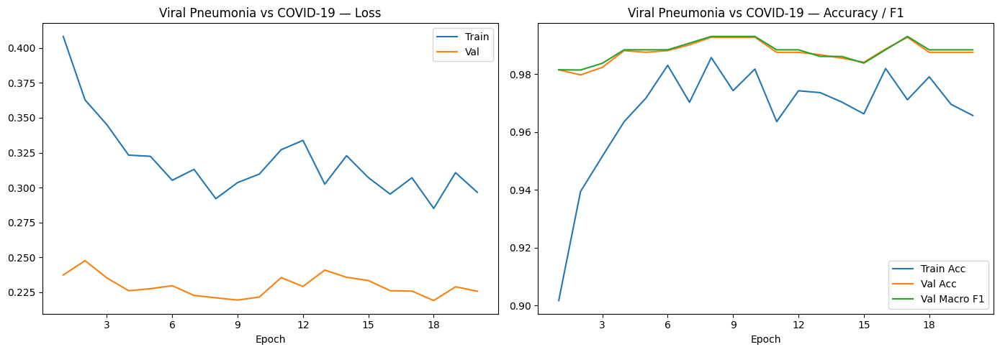

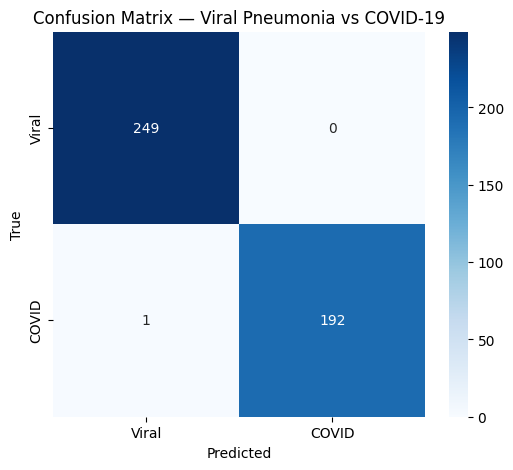

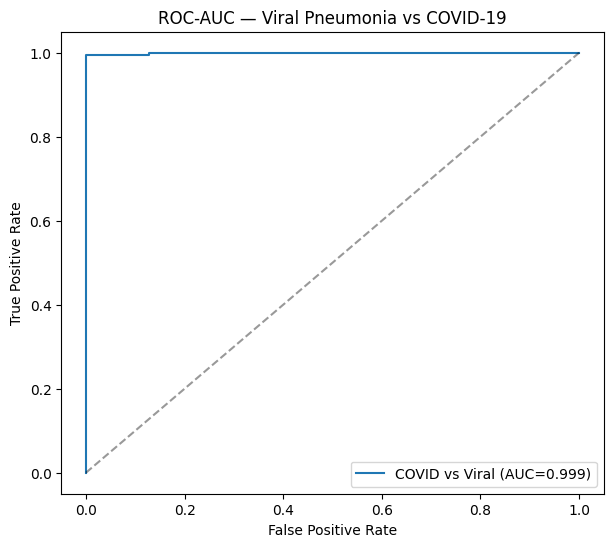

Misclassified: 1/442


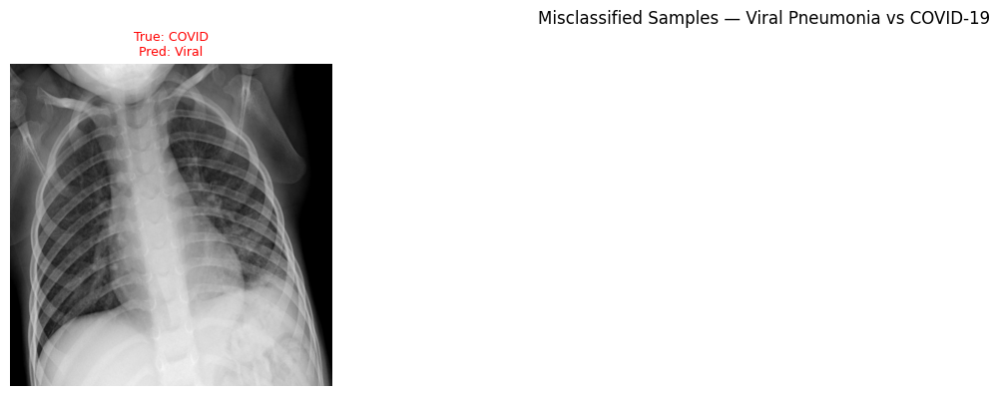

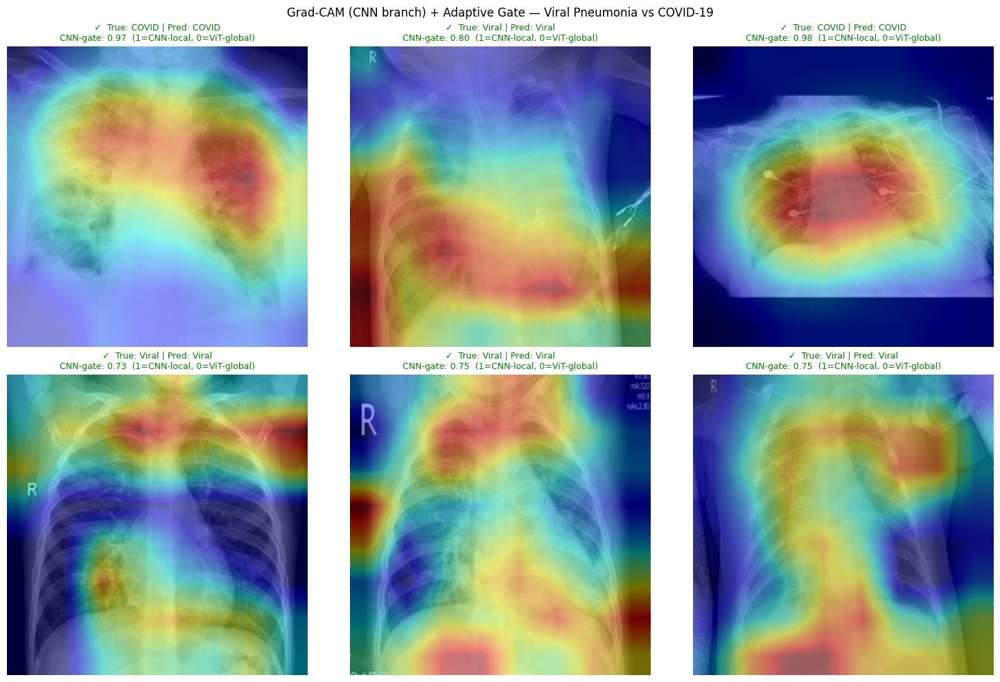

In [11]:
res_exp1 = run_experiment("exp1_viral_vs_covid", epochs=20)

## Experiment 2 — COVID vs Normal vs Bacterial

EXPERIMENT [exp2_covid_normal_bacterial]: COVID vs Normal vs Bacterial Pneumonia
Train: 5285 | Val: 1132 | Test: 1135
Class distribution (train): Counter({1: 2289, 2: 2100, 0: 896})
Class weights: tensor([1.6501, 0.6459, 0.7040], device='cuda:0')
Parameters: 30.45M

----- [exp2_covid_normal_bacterial] Epoch 1/20 -----


Train:   0%|          | 0/165 [00:00<?, ?it/s]

Val:   0%|          | 0/36 [00:00<?, ?it/s]

Train -> Loss:0.6642 Acc:0.8566 F1:0.8401
Val   -> Loss:0.4630 Acc:0.9645 F1:0.9698 AUROC:0.9983
-> Saved best model (Val Macro F1: 0.9698)

----- [exp2_covid_normal_bacterial] Epoch 2/20 -----


Train:   0%|          | 0/165 [00:00<?, ?it/s]

Val:   0%|          | 0/36 [00:00<?, ?it/s]

... (54 outputs left out)

Train -> Loss:0.4721 Acc:0.9703 F1:0.9641
Val   -> Loss:0.4234 Acc:0.9813 F1:0.9837 AUROC:0.9973


Val:   0%|          | 0/36 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ec7a3f149a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ec7a3f149a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16


========== TEST RESULTS — COVID vs Normal vs Bacterial Pneumonia ==========
Accuracy : 0.9882
Macro F1 : 0.9889
AUROC    : 0.9977

Classification Report (Test):
              precision    recall  f1-score   support

       COVID     1.0000    0.9948    0.9974       193
      Normal     0.9779    0.9919    0.9848       491
   Bacterial     0.9910    0.9778    0.9844       451

    accuracy                         0.9868      1135
   macro avg     0.9896    0.9882    0.9889      1135
weighted avg     0.9869    0.9868    0.9868      1135



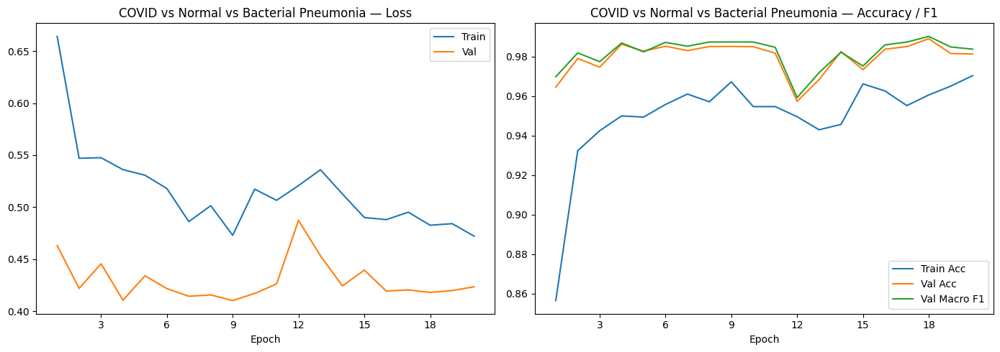

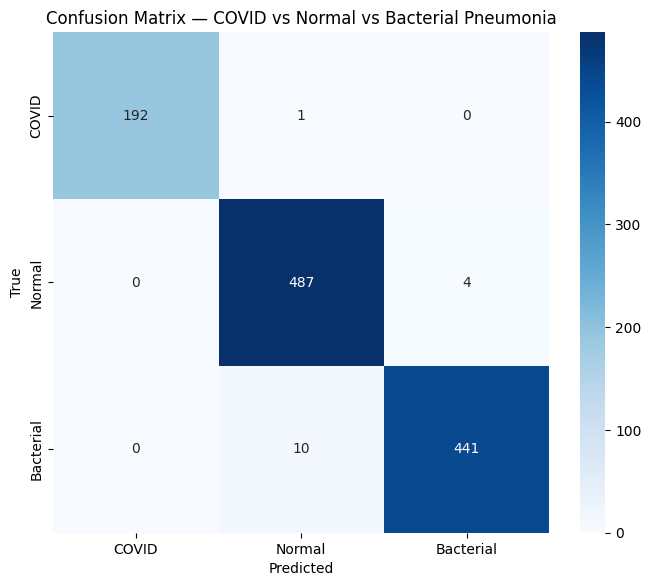

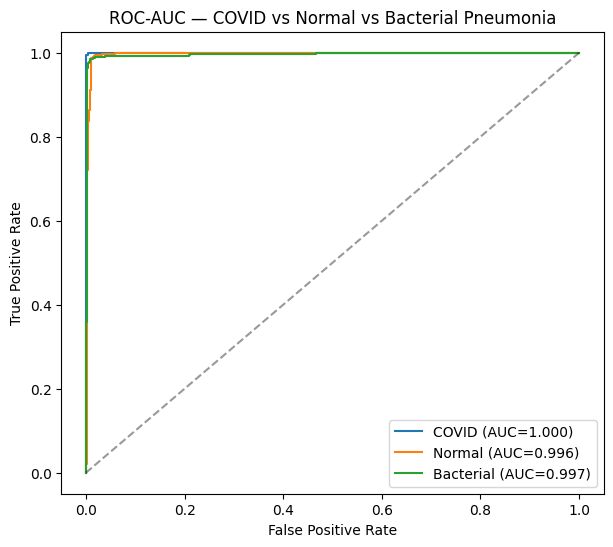

Misclassified: 15/1135


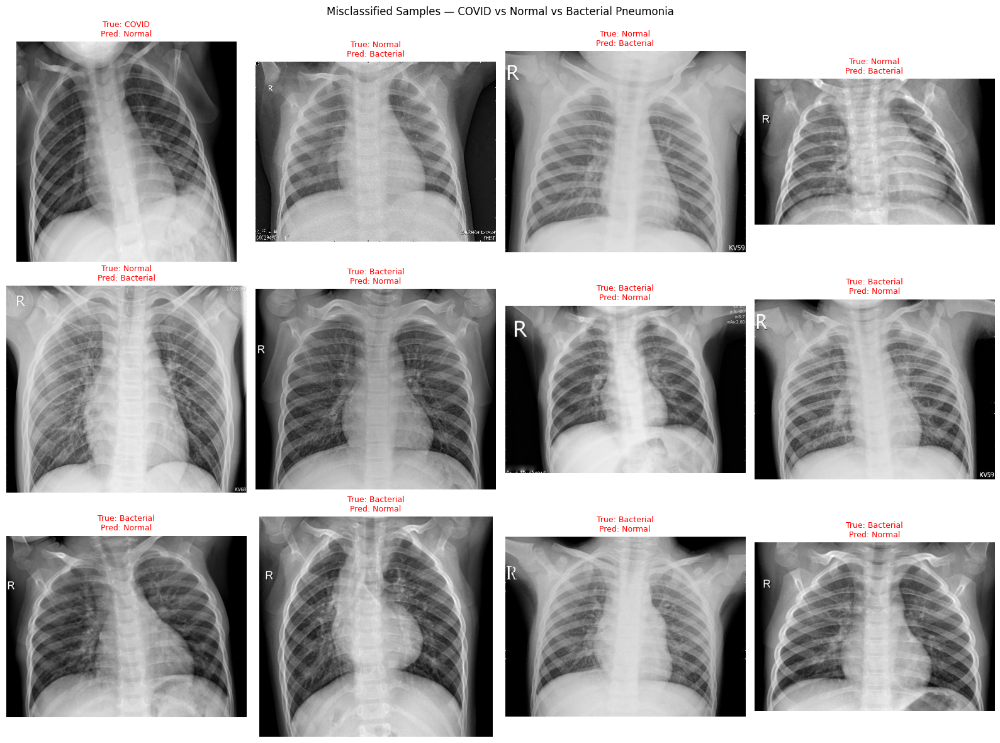

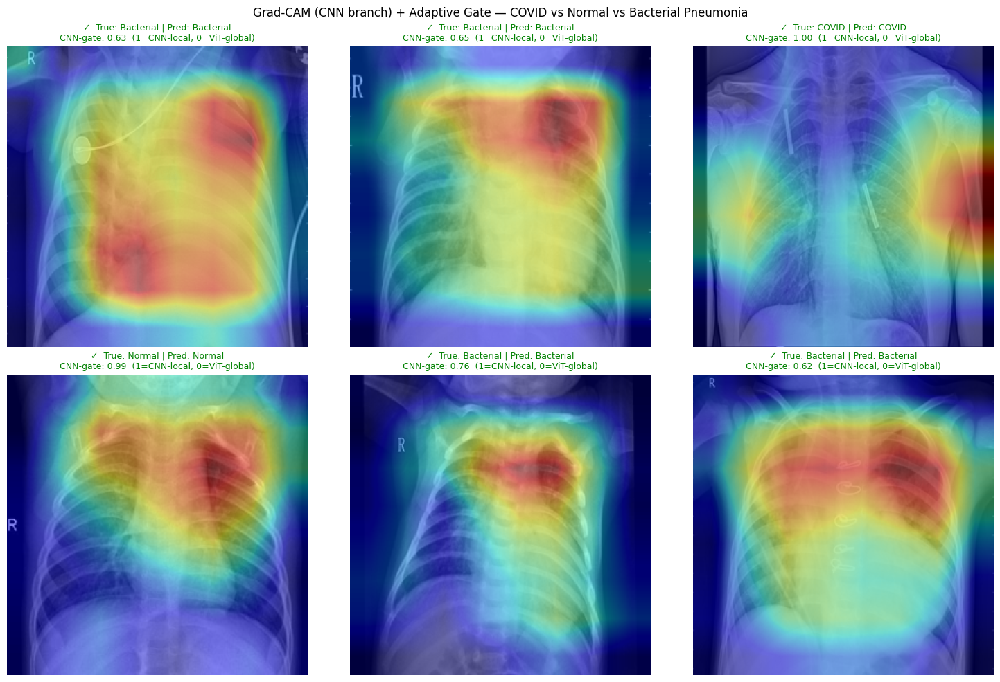

In [12]:
res_exp2 = run_experiment("exp2_covid_normal_bacterial", epochs=20)

## Experiment 3 — Normal vs Bacterial vs Viral vs COVID (4-class)

EXPERIMENT [exp3_all_4class]: Normal vs Bacterial vs Viral vs COVID (4-Class)
Train: 6444 | Val: 1380 | Test: 1384
Class distribution (train): Counter({0: 2289, 1: 2100, 2: 1159, 3: 896})
Class weights: tensor([0.6043, 0.6586, 1.1934, 1.5437], device='cuda:0')
Parameters: 30.45M

----- [exp3_all_4class] Epoch 1/40 -----


Train:   0%|          | 0/201 [00:00<?, ?it/s]

Val:   0%|          | 0/44 [00:00<?, ?it/s]

Train -> Loss:0.9626 Acc:0.6951 F1:0.6768
Val   -> Loss:0.7680 Acc:0.8283 F1:0.8319 AUROC:0.9543
-> Saved best model (Val Macro F1: 0.8319)

----- [exp3_all_4class] Epoch 2/40 -----


Train:   0%|          | 0/201 [00:00<?, ?it/s]

Val:   0%|          | 0/44 [00:00<?, ?it/s]

... (115 outputs left out)

Val:   0%|          | 0/44 [00:00<?, ?it/s]

Train -> Loss:0.6619 Acc:0.9143 F1:0.9058
Val   -> Loss:0.6286 Acc:0.9026 F1:0.9054 AUROC:0.9730


Val:   0%|          | 0/44 [00:00<?, ?it/s]


========== TEST RESULTS — Normal vs Bacterial vs Viral vs COVID (4-Class) ==========
Accuracy : 0.8995
Macro F1 : 0.9006
AUROC    : 0.9786

Classification Report (Test):
              precision    recall  f1-score   support

      Normal     0.9512    0.9919    0.9711       491
   Bacterial     0.8955    0.8736    0.8844       451
       Viral     0.7773    0.7430    0.7598       249
       COVID     0.9845    0.9896    0.9871       193

    accuracy                         0.9082      1384
   macro avg     0.9021    0.8995    0.9006      1384
weighted avg     0.9064    0.9082    0.9070      1384



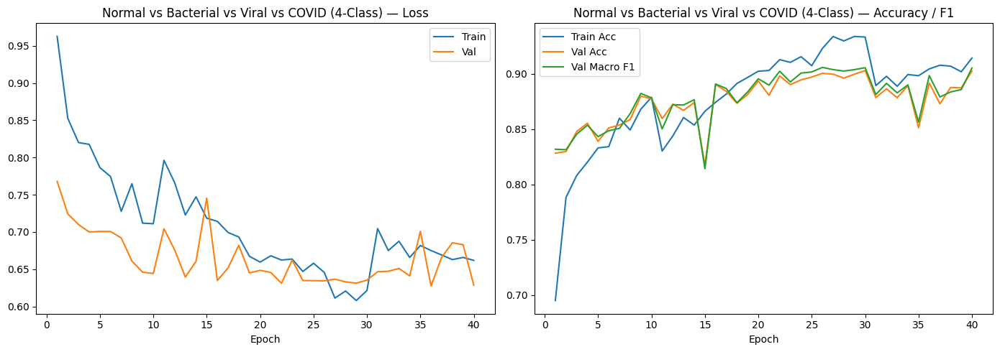

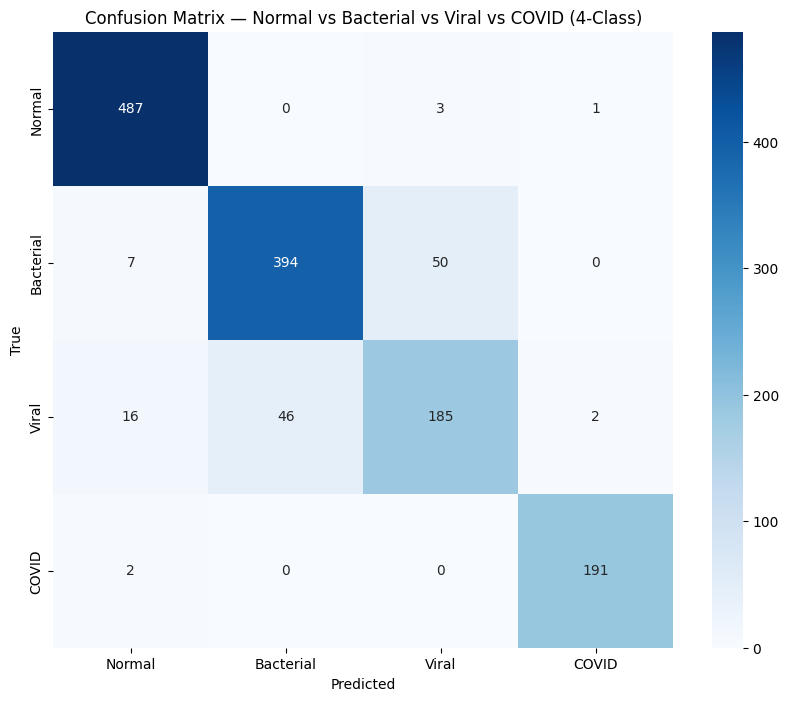

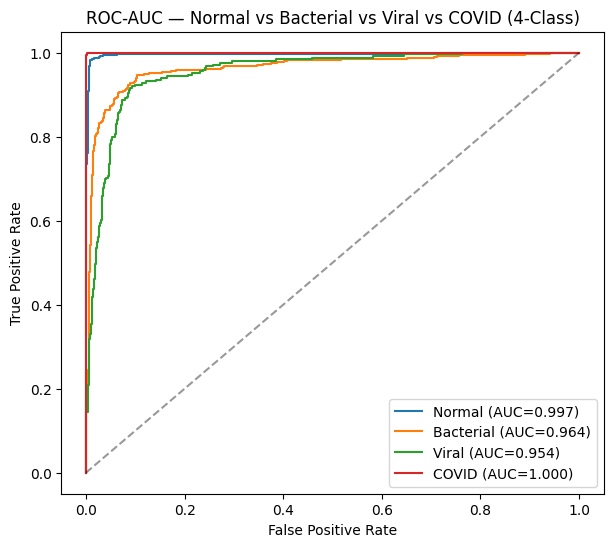

Misclassified: 127/1384


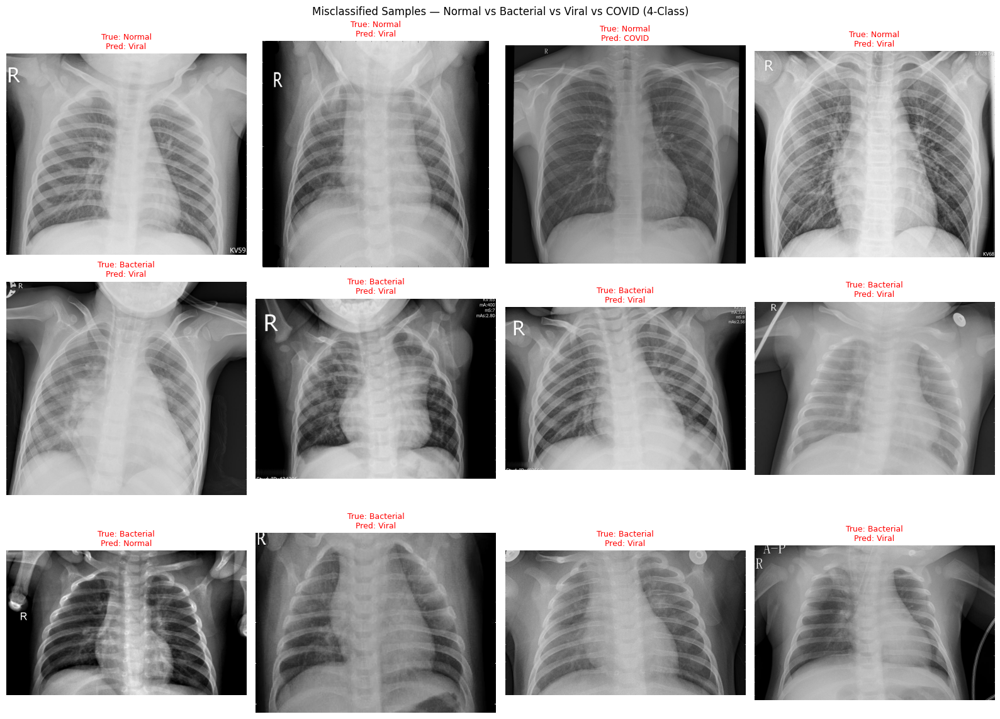

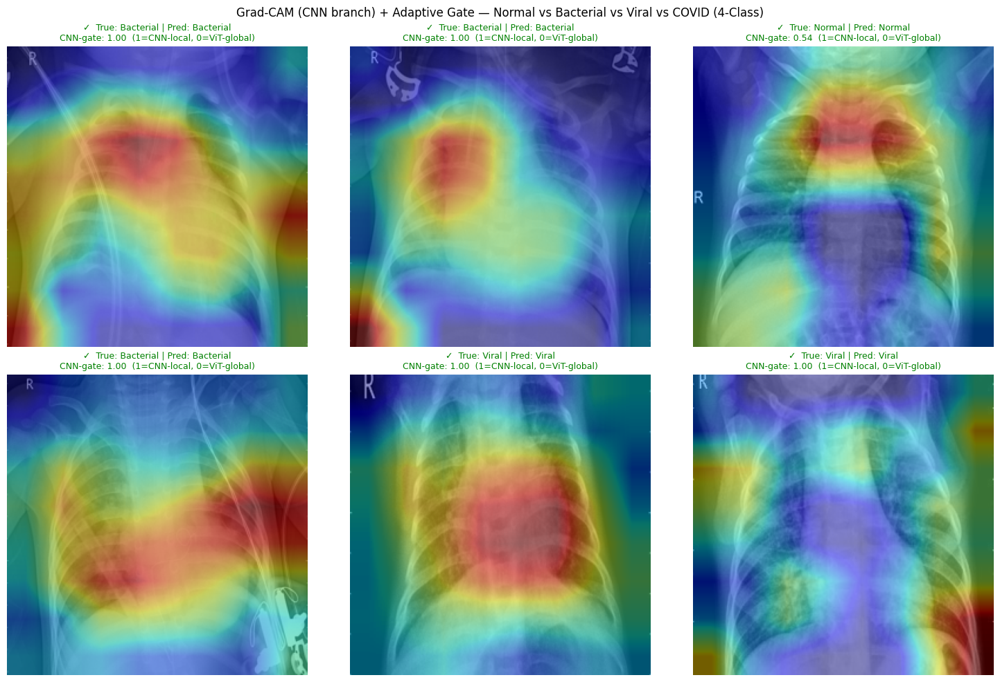

In [13]:
res_exp3 = run_experiment("exp3_all_4class", epochs=40)

## Experiment 4 — Normal vs Pneumonia (Bacterial + Viral merged)

EXPERIMENT [exp4_normal_vs_pneumonia]: Normal vs Pneumonia (Bacterial + Viral merged)
Train: 5548 | Val: 1188 | Test: 1191
Class distribution (train): Counter({1: 3259, 0: 2289})
Class weights: tensor([1.1748, 0.8252], device='cuda:0')
Parameters: 30.45M

----- [exp4_normal_vs_pneumonia] Epoch 1/20 -----


Train:   0%|          | 0/173 [00:00<?, ?it/s]

Val:   0%|          | 0/38 [00:00<?, ?it/s]

Train -> Loss:0.4366 Acc:0.8857 F1:0.8815
Val   -> Loss:0.2703 Acc:0.9722 F1:0.9698 AUROC:0.9962
-> Saved best model (Val Macro F1: 0.9698)

----- [exp4_normal_vs_pneumonia] Epoch 2/20 -----


Train:   0%|          | 0/173 [00:00<?, ?it/s]

Val:   0%|          | 0/38 [00:00<?, ?it/s]

... (56 outputs left out)

Train -> Loss:0.3120 Acc:0.9683 F1:0.9669
Val   -> Loss:0.2899 Acc:0.9633 F1:0.9571 AUROC:0.9856


Val:   0%|          | 0/38 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ec7a3f149a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ec7a3f149a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16


========== TEST RESULTS — Normal vs Pneumonia (Bacterial + Viral merged) ==========
Accuracy : 0.9825
Macro F1 : 0.9810
AUROC    : 0.9979

Classification Report (Test):
              precision    recall  f1-score   support

      Normal     0.9681    0.9878    0.9778       491
   Pneumonia     0.9913    0.9771    0.9842       700

    accuracy                         0.9815      1191
   macro avg     0.9797    0.9825    0.9810      1191
weighted avg     0.9817    0.9815    0.9816      1191



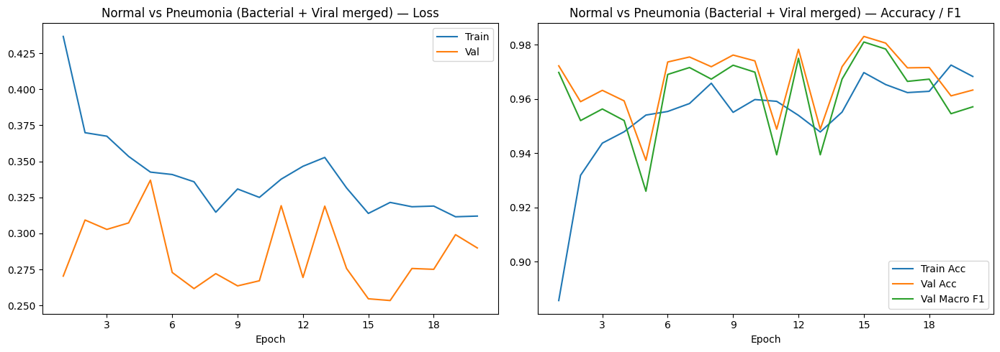

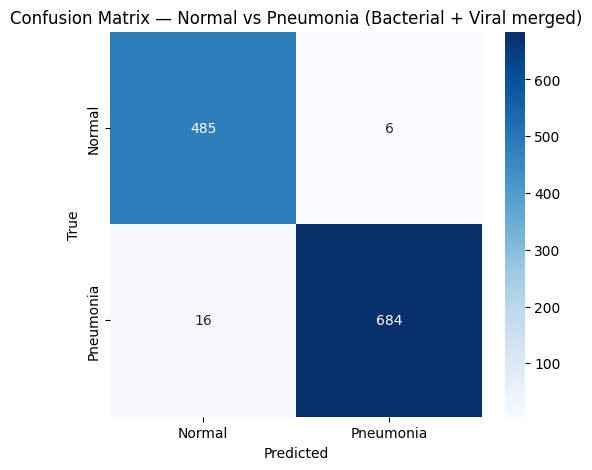

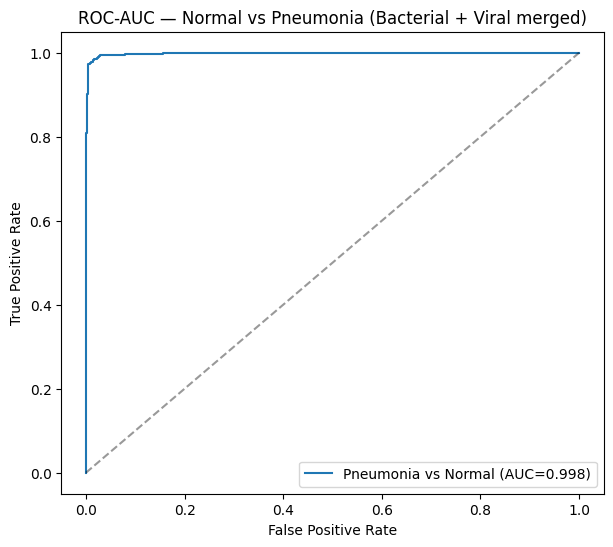

Misclassified: 22/1191


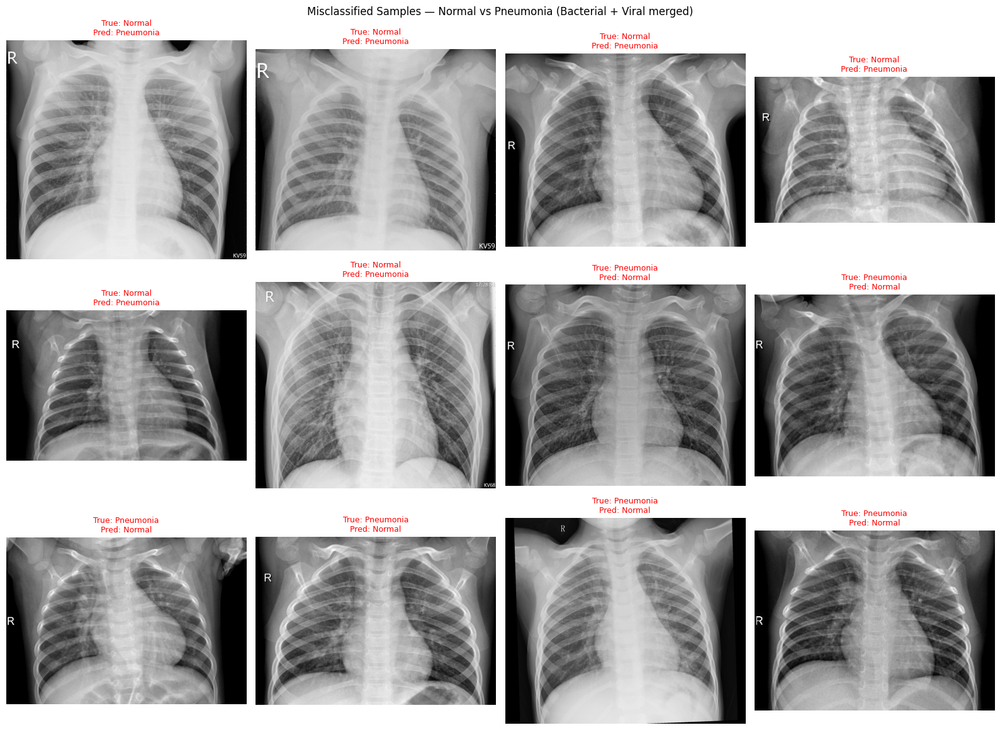

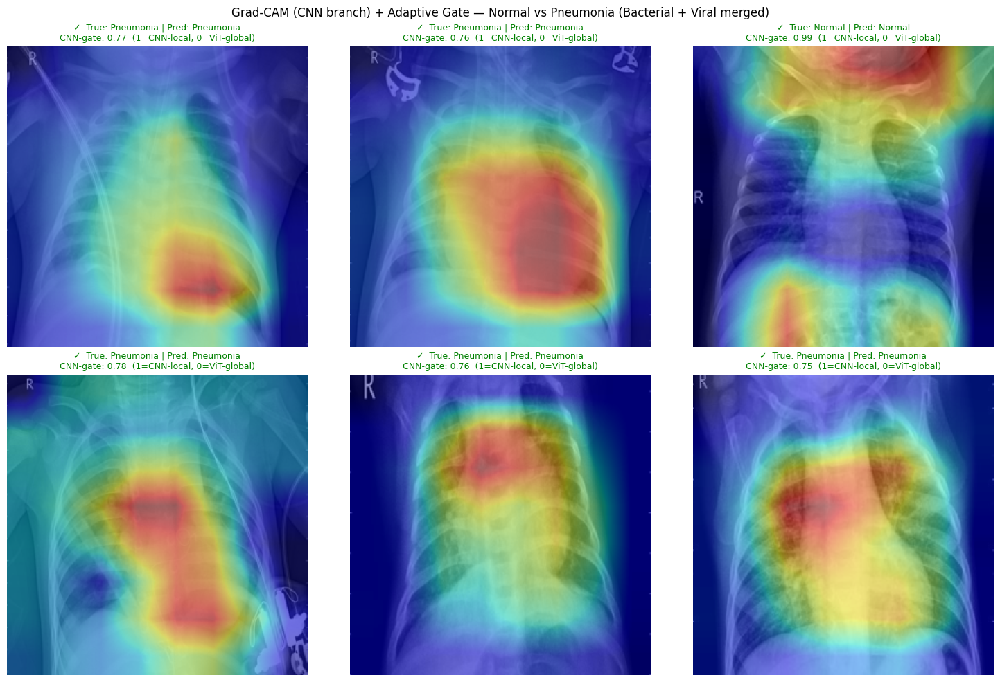

In [14]:
res_exp4 = run_experiment("exp4_normal_vs_pneumonia", epochs=20)